In [2]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/code/utils/")
cancer_type = "PAAD"
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

### Enrichment (seed=42)

In [6]:
top_features = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
len(top_features)

24

In [7]:
import re
rna_selected = [re.sub("^RNA_", "", g) for g in top_features if g.startswith("RNA_")]  # "^" 表示字串開頭，以空字串取代
meth_selected = [re.sub("^Meth_", "", g) for g in top_features if g.startswith("Meth_")]
mut_selected = [re.sub("^Mutation_", "", g) for g in top_features if g.startswith("Mutation_")]
cnv_selected = [int(re.sub("^CNV_", "", g)) for g in top_features if g.startswith("CNV_")] # 變成int

print("RNA:", rna_selected)
print("Meth:", meth_selected)
print("Mutation:", mut_selected)
print("CNV:", cnv_selected)

RNA: ['IL16', 'ADAMTS3', 'CD48', 'IKZF1', 'FCRLA', 'CLEC17A', 'FCRL1', 'CXCL13', 'CD79B', 'CD22', 'PAX5', 'TCL1A', 'FCER2', 'ETS1', 'GPR18', 'CCR4', 'MT-CO3', 'TGFB2', 'ADRB2', 'MT-ND3', 'PIK3CD', 'CR2', 'CCR2']
Meth: ['cg16829924']
Mutation: []
CNV: []


In [8]:
len(rna_selected)

23

In [9]:
from pymaftools import PivotTable
rna_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/rna_table.sqlite")
rna_table.feature_metadata[rna_table.index.isin(rna_selected)]

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite


,gene_name,gene_type,gene_name_x,gene_type_x,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,...,score,strand,phase,additional_info,gene_id,gene_type_y,gene_name_y,level,hgnc_id,havana_gene
feature,,,,,,,,,,,,,,,,,,,,,
ADAMTS3,ADAMTS3,protein_coding,ADAMTS3,protein_coding,95.843749,0.976791,0.160841,6.073023,1.255242e-09,1.528097e-07,...,.,-,.,"gene_id ""ENSG00000156140.10""; gene_type ""prote...",ENSG00000156140.10,protein_coding,ADAMTS3,2.0,HGNC:219,OTTHUMG00000129912.4
ADRB2,ADRB2,protein_coding,ADRB2,protein_coding,114.742811,0.726784,0.179049,4.059142,4.925340e-05,5.348035e-04,...,.,+,.,"gene_id ""ENSG00000169252.6""; gene_type ""protei...",ENSG00000169252.6,protein_coding,ADRB2,2.0,HGNC:286,OTTHUMG00000129933.1
CCR2,CCR2,protein_coding,CCR2,protein_coding,223.973237,1.323344,0.187292,7.065692,1.598174e-12,7.782287e-10,...,.,+,.,"gene_id ""ENSG00000121807.6""; gene_type ""protei...",ENSG00000121807.6,protein_coding,CCR2,2.0,HGNC:1603,OTTHUMG00000156466.3
CCR4,CCR4,protein_coding,CCR4,protein_coding,183.571519,1.516474,0.231090,6.562271,5.299453e-11,1.313795e-08,...,.,+,.,"gene_id ""ENSG00000183813.7""; gene_type ""protei...",ENSG00000183813.7,protein_coding,CCR4,2.0,HGNC:1605,OTTHUMG00000130752.3
CD22,CD22,protein_coding,CD22,protein_coding,727.131120,1.868959,0.266136,7.022564,2.178337e-12,1.008995e-09,...,.,+,.,"gene_id ""ENSG00000012124.17""; gene_type ""prote...",ENSG00000012124.17,protein_coding,CD22,1.0,HGNC:1643,OTTHUMG00000183298.5
CD48,CD48,protein_coding,CD48,protein_coding,343.661684,1.339249,0.216149,6.195941,5.793790e-10,8.150361e-08,...,.,-,.,"gene_id ""ENSG00000117091.10""; gene_type ""prote...",ENSG00000117091.10,protein_coding,CD48,2.0,HGNC:1683,OTTHUMG00000024009.3
CD79B,CD79B,protein_coding,CD79B,protein_coding,312.954274,1.688729,0.275397,6.131984,8.678972e-10,1.128920e-07,...,.,-,.,"gene_id ""ENSG00000007312.13""; gene_type ""prote...",ENSG00000007312.13,protein_coding,CD79B,2.0,HGNC:1699,OTTHUMG00000172294.3
CLEC17A,CLEC17A,protein_coding,CLEC17A,protein_coding,89.408525,1.996170,0.308527,6.470008,9.799759e-11,2.045134e-08,...,.,+,.,"gene_id ""ENSG00000187912.12""; gene_type ""prote...",ENSG00000187912.12,protein_coding,CLEC17A,2.0,HGNC:34520,OTTHUMG00000169312.1
CR2,CR2,protein_coding,CR2,protein_coding,1536.934733,2.862006,0.423164,6.763354,1.348332e-11,4.414856e-09,...,.,+,.,"gene_id ""ENSG00000117322.18""; gene_type ""prote...",ENSG00000117322.18,protein_coding,CR2,1.0,HGNC:2336,OTTHUMG00000036307.3


In [10]:
selected_type = (
    pd.Series(rna_table.subset(features=rna_selected).feature_metadata['change'])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(selected_type)

change
UP     16
NOT     7
Name: count, dtype: int64


In [11]:
from pymaftools import PivotTable
meth_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/meth_table.sqlite")
meth_table.feature_metadata[meth_table.index.isin(meth_selected)]

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite


,AddressA,AddressB,Color,CpG_maf,CpG_rs,DHS,DMR,Enhancer,Forward_Sequence,HMM_Island,...,pos,strand,intercept,f,pval,qval,logFC,change,delta_beta,changeBeta
feature,,,,,,,,,,,,,,,,,,,,,
cg16829924,48698301,64800418.0,Red,None,None,NaN,NaN,1.0,ATGCTAAGGTGCTGGGCTATTGACAGTTTCACACATCACCCTTGGC...,NaN,...,36383991,-,0.533875,25.88853,9.217317e-07,0.000034,0.352903,NOT,0.147952,Hyper


In [12]:
selected_type = (
    pd.Series(meth_table.subset(features=meth_selected).feature_metadata['changeBeta'])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(selected_type)

changeBeta
Hyper    1
Name: count, dtype: int64


In [13]:
meth_table.feature_metadata[meth_table.index.isin(meth_selected)].UCSC_RefGene_Name

feature
cg16829924    PRR5L
Name: UCSC_RefGene_Name, dtype: str

In [14]:
probe_gene = meth_table.feature_metadata[meth_table.index.isin(meth_selected)].UCSC_RefGene_Name.tolist()
# 分割並去除重複
probe_gene_unique = set()
for gene in probe_gene:
    probe_gene_unique.update(gene.split(';'))
probe_gene_unique = list(probe_gene_unique)

for i in range(len(probe_gene_unique)):
    if probe_gene_unique[i] in rna_selected:
        print(probe_gene_unique[i])

In [15]:
from pymaftools import PivotTable
mut_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/mutation_table.sqlite")
mut_table.feature_metadata[mut_table.index.isin(mut_selected)]

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite


,AlteredSamples,BIOTYPE,Entrez_Gene_Id,Frame_Shift_Del,Frame_Shift_Ins,Gene,GeneID,In_Frame_Del,In_Frame_Ins,Missense_Mutation,...,gene_type,havana_gene,hgnc_id,level,phase,score,source,start,strand,total
feature,,,,,,,,,,,,,,,,,,,,,


In [16]:
from pymaftools import PivotTable
cnv_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_cluster_table_{random_seed}.sqlite")
cnv_table.feature_metadata[cnv_table.index.isin(cnv_selected)]

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite


,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
feature,,,,


In [ ]:
cnv_list = cnv_table.feature_metadata[cnv_table.index.isin(cnv_selected)].genes_in_cluster.tolist()
cnv_list = cnv_list[0].split(',')
cnv_list

In [18]:
gene_selected = rna_selected + probe_gene_unique + cnv_list

# 分割並去除重複
unique_genes = set()
for gene in gene_selected:
    unique_genes.update(gene.split(';'))

unique_genes = sorted(unique_genes)
unique_genes

['ADAMTS3',
 'ADRB2',
 'CCR2',
 'CCR4',
 'CD22',
 'CD48',
 'CD79B',
 'CLEC17A',
 'CR2',
 'CXCL13',
 'ETS1',
 'FCER2',
 'FCRL1',
 'FCRLA',
 'GPR18',
 'IKZF1',
 'IL16',
 'MT-CO3',
 'MT-ND3',
 'PAX5',
 'PIK3CD',
 'PRR5L',
 'TCL1A',
 'TGFB2']

In [ ]:
# 使用 gseapy (Enrichr)
import gseapy as gp
enr = gp.enrichr(gene_list=unique_genes,
                 gene_sets=['KEGG_2021_Human','GO_Biological_Process_2025'],  # 'GO_Cellular_Component_2025','GO_Molecular_Function_2025' 都沒有過 cutoff 的結果
                 organism='human',
                 outdir=f"enrichment_results_{cancer_type}_{random_seed}/all",  # 不寫檔案，只回傳結果
                 cutoff=0.05,  # adjust p-value cutoff
                 top_term=15)

# 顯示結果
print("GO BP top:")
print(enr.results[enr.results['Gene_set']=='GO_Biological_Process_2025'].head())
print("KEGG top:")
print(enr.results[enr.results['Gene_set']=='KEGG_2021_Human'].head())

GO BP top:
                     Gene_set  \
0  GO_Biological_Process_2025   
1  GO_Biological_Process_2025   
2  GO_Biological_Process_2025   
3  GO_Biological_Process_2025   
4  GO_Biological_Process_2025   

                                                Term Overlap   P-value  \
0                     B Cell Activation (GO:0042113)    2/96  0.000471   
1  Positive Regulation of cAMP/PKA Signal Transdu...     1/7  0.002448   
2  Negative Regulation of Systemic Arterial Blood...    1/10  0.003495   
3  Adenylate Cyclase-Activating Adrenergic Recept...    1/13  0.004542   
4  Regulation of cAMP/PKA Signal Transduction (GO...    1/14  0.004890   

   Adjusted P-value  Old P-value  Old Adjusted P-value  Odds Ratio  \
0          0.020740            0                     0   84.676596   
1          0.040925            0                     0  555.194444   
2          0.040925            0                     0  370.074074   
3          0.040925            0                     0  277.51388

In [20]:
enr.results[enr.results['Gene_set']=='KEGG_2021_Human']

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
517,KEGG_2021_Human,B cell receptor signaling pathway,5/81,7.271753e-07,0.000079,0,0,35.352063,499.669526,CD79B;CR2;CD19;PIK3CD;CD22
518,KEGG_2021_Human,Hematopoietic cell lineage,5/99,1.974346e-06,0.000079,0,0,28.556642,375.099295,FCER2;CR2;CD19;MS4A1;CD22
519,KEGG_2021_Human,Viral protein interaction with cytokine and cy...,5/100,2.075056e-06,0.000079,0,0,28.254623,369.726501,LTA;CCL19;CXCL13;CCR4;CCR2
520,KEGG_2021_Human,Cytokine-cytokine receptor interaction,7/295,2.452252e-06,0.000079,0,0,13.659722,176.463172,TGFB2;LTA;IL16;CCL19;CXCL13;CCR4;CCR2
521,KEGG_2021_Human,Chemokine signaling pathway,5/192,4.934142e-05,0.001273,0,0,14.287469,141.685213,PIK3CD;CCL19;CXCL13;CCR4;CCR2
...,...,...,...,...,...,...,...,...,...,...
641,KEGG_2021_Human,Salmonella infection,1/249,4.094641e-01,0.422567,0,0,1.938434,1.730840,PIK3CD
642,KEGG_2021_Human,Prion disease,1/273,4.388933e-01,0.449343,0,0,1.765244,1.453676,PIK3CD
643,KEGG_2021_Human,MAPK signaling pathway,1/294,4.634657e-01,0.470764,0,0,1.636977,1.258872,TGFB2
644,KEGG_2021_Human,Human papillomavirus infection,1/331,5.042286e-01,0.508168,0,0,1.450702,0.993333,PIK3CD


In [ ]:
fig = gp.barplot(
    enr.results,
    title='GO_Biological_Process_2025',
    figsize=(6, 4),
    top_term=5
)
fig.set_title('GO_Biological_Process_2025', fontsize=10)
fig.tick_params(axis='both', labelsize=14)

#plt.savefig('./tiff_figure/paper/GO_PAAD.tiff', dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})

In [22]:
gp.get_library_name()

['ARCHS4_Cell-lines',
 'ARCHS4_IDG_Coexp',
 'ARCHS4_Kinases_Coexp',
 'ARCHS4_TFs_Coexp',
 'ARCHS4_Tissues',
 'Achilles_fitness_decrease',
 'Achilles_fitness_increase',
 'Aging_Perturbations_from_GEO_down',
 'Aging_Perturbations_from_GEO_up',
 'Allen_Brain_Atlas_10x_scRNA_2021',
 'Allen_Brain_Atlas_down',
 'Allen_Brain_Atlas_up',
 'Azimuth_2023',
 'Azimuth_Cell_Types_2021',
 'BioCarta_2013',
 'BioCarta_2015',
 'BioCarta_2016',
 'BioPlanet_2019',
 'BioPlex_2017',
 'CCLE_Proteomics_2020',
 'CM4AI_U2OS_Protein_Localization_Assemblies',
 'COMPARTMENTS_Curated_2025',
 'COMPARTMENTS_Experimental_2025',
 'CORUM',
 'COVID-19_Related_Gene_Sets',
 'COVID-19_Related_Gene_Sets_2021',
 'Cancer_Cell_Line_Encyclopedia',
 'CellMarker_2024',
 'CellMarker_Augmented_2021',
 'ChEA_2013',
 'ChEA_2015',
 'ChEA_2016',
 'ChEA_2022',
 'Chromosome_Location',
 'Chromosome_Location_hg19',
 'ClinVar_2019',
 'ClinVar_2025',
 'DGIdb_Drug_Targets_2024',
 'DSigDB',
 'Data_Acquisition_Method_Most_Popular_Genes',
 'DepMa

### Differentially Expressed in Each Omics

#### CNV

In [19]:
cancer_type = "PAAD"
random_seed = 42

In [21]:
# CNV cluster table
cnv_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_cluster_table_{random_seed}.sqlite")
train_samples = cnv_table.sample_metadata[f"split_{random_seed}"] == "train" 
cnv_train = cnv_table.subset(samples=train_samples)

# CNV gene table
cnv_gene_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_table.sqlite")
cnv_gene_train = cnv_gene_table.subset(samples=train_samples)

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table.sqlite


In [22]:
import re
import pandas as pd

target_genes = [
    'OR11H12', 'OR11H2', 'POTEG', 'POTEM', 'OR4Q3',
    'OR4M1', 'OR4N2', 'OR4K2', 'OR4K5', 'OR4K1', 'OR4K15'
]

rows = []
for cluster_id, gene_str in cnv_table.feature_metadata["genes_in_cluster"].dropna().items():
    genes = [g.strip() for g in re.split(r"[;,]", str(gene_str)) if g.strip()]
    for g in genes:
        if g in target_genes:
            rows.append({
                "Cluster": cluster_id,
                "Gene": g
            })

result_df = pd.DataFrame(rows).drop_duplicates().sort_values(["Cluster", "Gene"])
display(result_df)

# 如果想看哪些 gene 沒找到
found_genes = set(result_df["Gene"]) if not result_df.empty else set()
not_found = [g for g in target_genes if g not in found_genes]
print("Not found:", not_found)

,Cluster,Gene
0,138,OR11H12
1,138,OR11H2
9,138,OR4K1
10,138,OR4K15
7,138,OR4K2
8,138,OR4K5
5,138,OR4M1
6,138,OR4N2
4,138,OR4Q3
2,138,POTEG


Not found: []


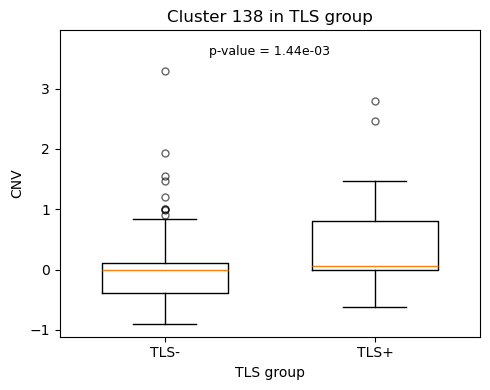

In [24]:
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

# 取出 cluster 138 的數值（對應所有 sample）
cluster_138_values = cnv_train.loc[138]
group0 = cluster_138_values[cnv_gene_train.sample_metadata["TLS"] == 0]
group1 = cluster_138_values[cnv_gene_train.sample_metadata["TLS"] == 1]
_, p_value = mannwhitneyu(group0, group1, alternative="two-sided", method="auto")

fig, ax = plt.subplots(figsize=(5, 4))
bp = ax.boxplot(
    [group0, group1],
    tick_labels=["TLS-", "TLS+"],
    widths=0.6,
    flierprops={"marker": "o", "markersize": 5, "alpha": 0.6}
)

# p-value 標註
y_min = min(group0.min(), group1.min())
y_max = max(group0.max(), group1.max())
y_range = y_max - y_min if y_max > y_min else 1.0
ax.text(1.5, y_max + 0.05 * y_range, f"p-value = {p_value:.2e}", ha="center", va="bottom", fontsize=9)


ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.16 * y_range)
ax.set_xlabel("TLS group")
ax.set_ylabel("CNV")
ax.set_title("Cluster 138 in TLS group")
plt.tight_layout()
plt.show()

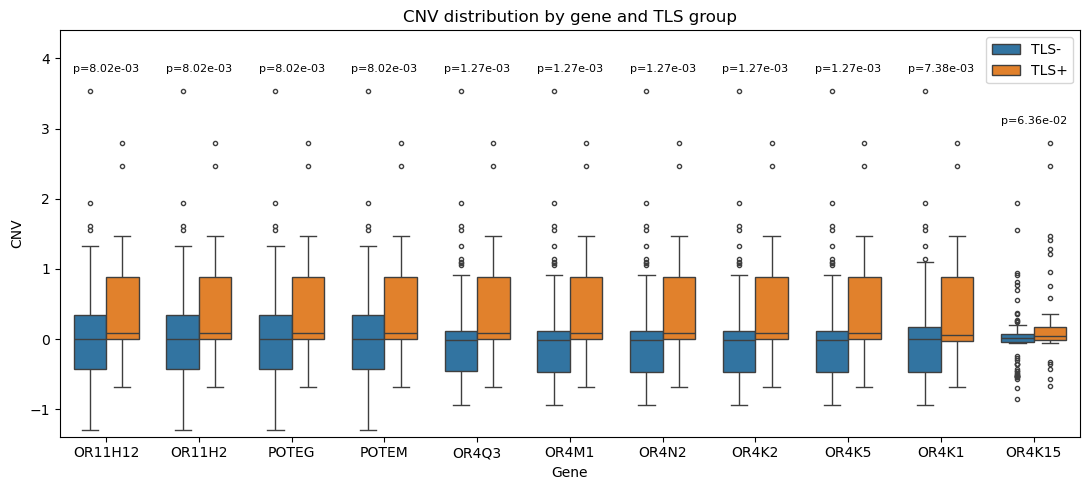

,p_value,adjusted_p_value
OR11H12,0.007292,0.008021
OR11H2,0.007292,0.008021
POTEG,0.007292,0.008021
POTEM,0.007292,0.008021
OR4Q3,0.000577,0.001270
OR4M1,0.000497,0.001270
OR4N2,0.000497,0.001270
OR4K2,0.000497,0.001270
OR4K5,0.000497,0.001270
OR4K1,0.004023,0.007376


In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

genes = ['OR11H12','OR11H2','POTEG','POTEM','OR4Q3','OR4M1','OR4N2','OR4K2','OR4K5','OR4K1','OR4K15']

rows = []
pvals = {}
for g in genes:
    vals = cnv_gene_train.loc[g]
    group0 = vals[cnv_gene_train.sample_metadata["TLS"] == 0]
    group1 = vals[cnv_gene_train.sample_metadata["TLS"] == 1]
    _, p_value = mannwhitneyu(group0, group1, alternative='two-sided', method='auto')
    pvals[g] = p_value

    rows.append(pd.DataFrame({
        "Gene": g,
        "CNV": vals.values,
        "TLS": cnv_gene_train.sample_metadata["TLS"].values
    }))

# 多重比較校正（BH-FDR）
pvals_series = pd.Series(pvals)
_, pvals_adj, _, _ = multipletests(pvals_series.values, alpha=0.05, method='fdr_bh')
pvals_adj = pd.Series(pvals_adj, index=pvals_series.index)

plot_df = pd.concat(rows, axis=0, ignore_index=True)
plot_df["TLS"] = plot_df["TLS"].map({0: "TLS-", 1: "TLS+"})
plot_df["Gene"] = pd.Categorical(plot_df["Gene"], categories=genes, ordered=True)

plt.figure(figsize=(11, 5))
ax = sns.boxplot(
    data=plot_df,
    x="Gene",
    y="CNV",
    hue="TLS",
    #palette={"TLS-": "#2065B4", "TLS+": "#CC252D"},
    width=0.7,
    fliersize=3
)

# 在每個 gene 的兩組箱型圖正上方標 raw p 與 adj p
y_global_min = plot_df["CNV"].min()
y_global_max = plot_df["CNV"].max()
y_global_range = y_global_max - y_global_min if y_global_max > y_global_min else 1.0

for i, g in enumerate(genes):
    y_gene_max = plot_df.loc[plot_df["Gene"] == g, "CNV"].max()
    y_text = y_gene_max + 0.05 * y_global_range
    ax.text(i, y_text, f"p={pvals_adj[g]:.2e}", ha="center", va="bottom", fontsize=8)

# 增加上方空間避免文字被裁切
ax.set_ylim(y_global_min - 0.02 * y_global_range, y_global_max + 0.18 * y_global_range)

plt.xticks(rotation=0, ha="center")
plt.xlabel("Gene")
plt.ylabel("CNV")
plt.title("CNV distribution by gene and TLS group")
plt.legend(title="", loc="upper right")
plt.tight_layout()
plt.show()

# 若需要匯出統計表
stats_df = pd.DataFrame({"p_value": pvals_series, "adjusted_p_value": pvals_adj}).loc[genes]
stats_df

#### RNA

In [ ]:
# RNA table
rna_table = PivotTable.read_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/rna_table.sqlite")
train_samples = rna_table.sample_metadata[f"split_{random_seed}"] == "train" 
rna_train = rna_table.subset(samples=train_samples)

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/all/table/rna_table.sqlite


In [ ]:
top_features_rna = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
rna_selected = [re.sub(r"^RNA_", "", x) for x in top_features_rna if x.startswith("RNA_")]
rna_selected

['FCRLA',
 'FCRL1',
 'CNR2',
 'CD19',
 'FCER2',
 'CCR7',
 'TCL1A',
 'CLEC17A',
 'NOB1',
 'PAX5',
 'MS4A1',
 'CR2',
 'NIBAN3']

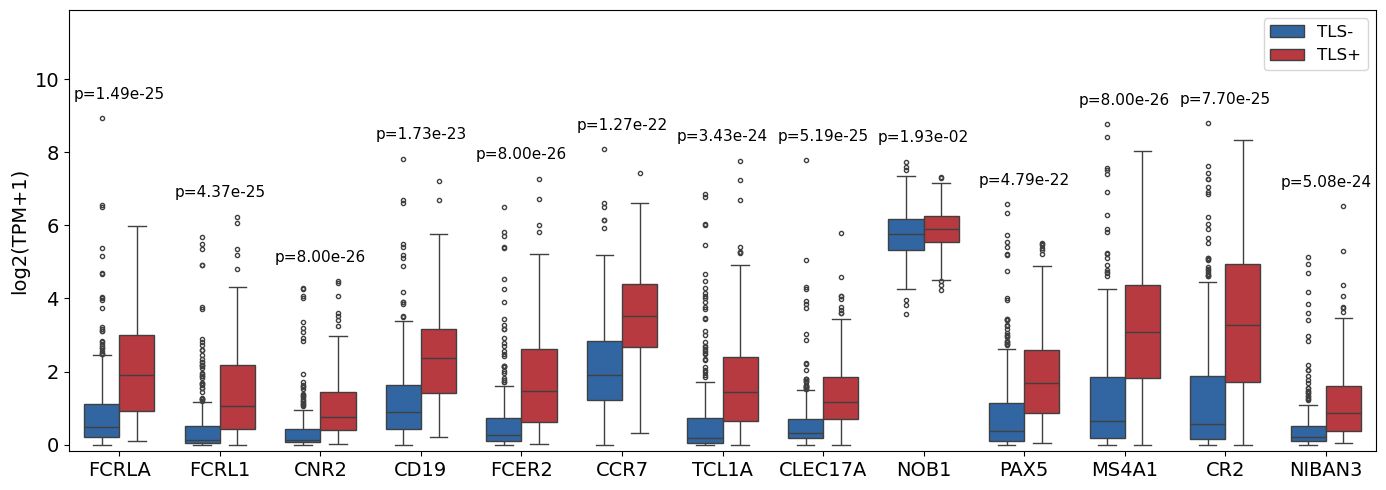

,p_value,adjusted_p_value
FCRLA,4.596276e-26,1.493790e-25
FCRL1,1.682144e-25,4.373575e-25
CNR2,9.577329e-27,7.995629e-26
CD19,1.327648e-23,1.725942e-23
FCER2,1.845145e-26,7.995629e-26
CCR7,1.078014e-22,1.274017e-22
TCL1A,2.113040e-24,3.433690e-24
CLEC17A,2.394674e-25,5.188461e-25
NOB1,1.933940e-02,1.933940e-02
PAX5,4.422894e-22,4.791468e-22


In [33]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

rows = []
pvals = {}
for g in rna_selected:
    vals = rna_train.loc[g]
    group0 = vals[rna_train.sample_metadata["TLS"] == 0]
    group1 = vals[rna_train.sample_metadata["TLS"] == 1]
    _, p_value = mannwhitneyu(group0, group1, alternative='two-sided', method='auto')
    pvals[g] = p_value

    rows.append(pd.DataFrame({
        "Gene": g,
        "log2(TPM)": vals.values,
        "TLS": rna_train.sample_metadata["TLS"].values
    }))

# 多重比較校正（BH-FDR）
pvals_series = pd.Series(pvals)
_, pvals_adj, _, _ = multipletests(pvals_series.values, alpha=0.05, method='fdr_bh')
pvals_adj = pd.Series(pvals_adj, index=pvals_series.index)

plot_df = pd.concat(rows, axis=0, ignore_index=True)
plot_df["TLS"] = plot_df["TLS"].map({0: "TLS-", 1: "TLS+"})
plot_df["Gene"] = pd.Categorical(plot_df["Gene"], categories=rna_selected, ordered=True)

plt.figure(figsize=(14, 5))
ax = sns.boxplot(
    data=plot_df,
    x="Gene",
    y="log2(TPM)",
    hue="TLS",
    order=rna_selected,
    hue_order=["TLS-", "TLS+"],
    palette={"TLS-": "#2065B4", "TLS+": "#CC252D"},
    width=0.7,
    fliersize=3
)

# 在每個 Probe 的兩組箱型圖正上方標 raw p 與 adj p
y_global_min = plot_df["log2(TPM)"].min()
y_global_max = plot_df["log2(TPM)"].max()
y_global_range = y_global_max - y_global_min if y_global_max > y_global_min else 1.0

for i, g in enumerate(rna_selected):
    y_gene_max = plot_df.loc[plot_df["Gene"] == g, "log2(TPM)"].max()
    y_text = y_gene_max + 0.05 * y_global_range
    ax.text(i, y_text, f"p={pvals_adj[g]:.2e}", ha="center", va="bottom", fontsize=11)

# 增加上方空間避免文字被裁切
ax.set_ylim(y_global_min - 0.02 * y_global_range, y_global_max + 0.33 * y_global_range)

plt.xticks(rotation=0, ha="center")
plt.xlabel(None, fontsize=14)
plt.ylabel("log2(TPM+1)", fontsize=14)
plt.tick_params(axis='both', labelsize=14)
#plt.title("log2(TPM+1) distribution by gene and TLS group", fontsize=18)
plt.legend(title="", loc="upper right", fontsize=12)
plt.tight_layout()
#plt.savefig('./tiff_figure/pooled_expression.tiff', dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

# 若需要匯出統計表
stats_df = pd.DataFrame({"p_value": pvals_series, "adjusted_p_value": pvals_adj}).loc[rna_selected]
stats_df

#### Methylation

In [38]:
# Meth table
meth_table = PivotTable.read_sqlite(db_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/meth_table.sqlite")
train_samples = meth_table.sample_metadata[f"split_{random_seed}"] == "train" 
meth_train = meth_table.subset(samples=train_samples)

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite


In [39]:
top_features_meth = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
meth_selected = [re.sub("^Meth_", "", g) for g in top_features_meth if g.startswith("Meth_")]
meth_selected

['cg16829924']

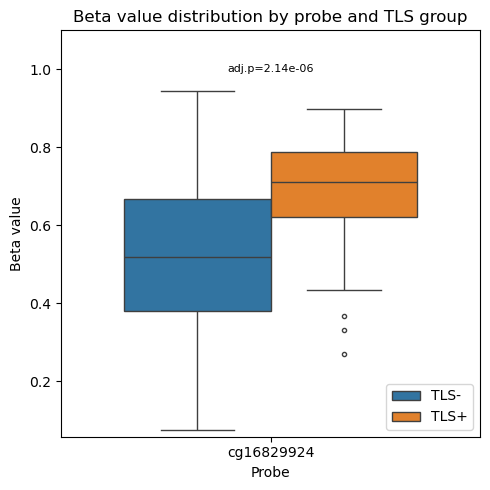

,p_value,adjusted_p_value
cg16829924,0.000002,0.000002


In [48]:
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

rows = []
pvals = {}
for g in meth_selected:
    vals = meth_train.loc[g]
    group0 = vals[meth_train.sample_metadata["TLS"] == 0]
    group1 = vals[meth_train.sample_metadata["TLS"] == 1]
    _, p_value = mannwhitneyu(group0, group1, alternative='two-sided', method='auto')
    pvals[g] = p_value

    rows.append(pd.DataFrame({
        "Probe": g,
        "Beta value": vals.values,
        "TLS": meth_train.sample_metadata["TLS"].values
    }))

# 多重比較校正（BH-FDR）
pvals_series = pd.Series(pvals)
_, pvals_adj, _, _ = multipletests(pvals_series.values, alpha=0.05, method='fdr_bh')
pvals_adj = pd.Series(pvals_adj, index=pvals_series.index)

plot_df = pd.concat(rows, axis=0, ignore_index=True)
plot_df["TLS"] = plot_df["TLS"].map({0: "TLS-", 1: "TLS+"})
plot_df["Probe"] = pd.Categorical(plot_df["Probe"], categories=meth_selected, ordered=True)

plt.figure(figsize=(5, 5))
ax = sns.boxplot(
    data=plot_df,
    x="Probe",
    y="Beta value",
    hue="TLS",
    #palette={"TLS-": "#2065B4", "TLS+": "#CC252D"},
    width=0.7,
    fliersize=3
)

# 在每個 Probe 的兩組箱型圖正上方標 raw p 與 adj p
y_global_min = plot_df["Beta value"].min()
y_global_max = plot_df["Beta value"].max()
y_global_range = y_global_max - y_global_min if y_global_max > y_global_min else 1.0

for i, g in enumerate(meth_selected):
    y_probe_max = plot_df.loc[plot_df["Probe"] == g, "Beta value"].max()
    y_text = y_probe_max + 0.05 * y_global_range
    ax.text(i, y_text, f"adj.p={pvals_adj[g]:.2e}", ha="center", va="bottom", fontsize=8)

# 增加上方空間避免文字被裁切
ax.set_ylim(y_global_min - 0.02 * y_global_range, y_global_max + 0.18 * y_global_range)

plt.xticks(rotation=0, ha="center")
plt.xlabel("Probe")
plt.ylabel("Beta value")
plt.title("Beta value distribution by probe and TLS group")
plt.legend(title="", loc="lower right")
plt.tight_layout()
plt.show()

# 若需要匯出統計表
stats_df = pd.DataFrame({"p_value": pvals_series, "adjusted_p_value": pvals_adj}).loc[meth_selected]
stats_df

In [49]:
meth_table.feature_metadata.loc[meth_table.index.isin(meth_selected), ("UCSC_RefGene_Group","UCSC_RefGene_Name")]

,UCSC_RefGene_Group,UCSC_RefGene_Name
feature,,
cg16829924,5'UTR,PRR5L


Valid probe-gene pairs: 1


,Probe,Gene,ProbeGene
0,cg16829924,PRR5L,cg16829924/PRR5L


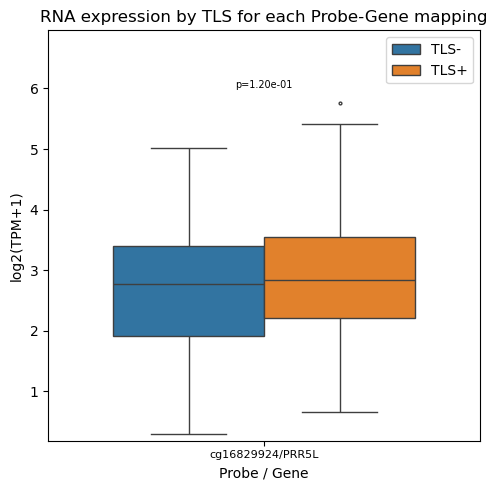

,Probe,Gene,ProbeGene,p_value,adjusted_p_value
0,cg16829924,PRR5L,cg16829924/PRR5L,0.119775,0.119775


In [52]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# 1) 取 meth_selected 的 probe-gene 註解
probe_gene_series = meth_train.feature_metadata[meth_train.index.isin(meth_selected)].UCSC_RefGene_Name

# 2) 展開成每個配對都保留 (probe, gene)
pairs = []
for probe, gene_str in probe_gene_series.items():
    genes = [g.strip() for g in re.split(r"[;,]", str(gene_str)) if g.strip()]
    for g in genes:
        pairs.append((probe, g))

pairs_df = pd.DataFrame(pairs, columns=["Probe", "Gene"]).drop_duplicates()

# 只保留 rna_train 中真的存在的 gene
pairs_df = pairs_df[pairs_df["Gene"].isin(rna_train.index)].copy()
pairs_df["ProbeGene"] = pairs_df["Probe"] + "/" + pairs_df["Gene"]

print(f"Valid probe-gene pairs: {len(pairs_df)}")
display(pairs_df.head())

# 3) 逐 pair 做檢定並建立作圖資料
rows = []
pvals = {}
for _, row in pairs_df.iterrows():
    probe = row["Probe"]
    gene = row["Gene"]
    key = row["ProbeGene"]

    vals = rna_train.loc[gene]
    group0 = vals[rna_train.sample_metadata["TLS"] == 0]
    group1 = vals[rna_train.sample_metadata["TLS"] == 1]

    _, p = mannwhitneyu(group0, group1, alternative="two-sided", method="auto")
    pvals[key] = p

    rows.append(pd.DataFrame({
        "ProbeGene": key,              # x軸同時顯示 probe + gene
        "Probe": probe,
        "Gene": gene,
        "log2(TPM)": vals.values,
        "TLS": rna_train.sample_metadata["TLS"].values
    }))

plot_df = pd.concat(rows, axis=0, ignore_index=True)
plot_df["TLS"] = plot_df["TLS"].map({0: "TLS-", 1: "TLS+"})

# 4) BH-FDR（以所有 probe-gene pair 數量校正）
pvals_series = pd.Series(pvals)
_, pvals_adj, _, _ = multipletests(pvals_series.values, alpha=0.05, method="fdr_bh")
pvals_adj = pd.Series(pvals_adj, index=pvals_series.index)

# 5) 畫圖
order = pairs_df["ProbeGene"].tolist()
plot_df["ProbeGene"] = pd.Categorical(plot_df["ProbeGene"], categories=order, ordered=True)

plt.figure(figsize=(5, 5))
ax = sns.boxplot(
    data=plot_df,
    x="ProbeGene",
    y="log2(TPM)",
    hue="TLS",
    width=0.7,
    fliersize=2
)

# 標註調整後 p 值
ymin, ymax = plot_df["log2(TPM)"].min(), plot_df["log2(TPM)"].max()
yr = ymax - ymin if ymax > ymin else 1.0
for i, k in enumerate(order):
    yk = plot_df.loc[plot_df["ProbeGene"] == k, "log2(TPM)"].max()
    ax.text(i, yk + 0.04 * yr, f"p={pvals_adj[k]:.2e}", ha="center", va="bottom", fontsize=7)

ax.set_ylim(ymin - 0.02 * yr, ymax + 0.22 * yr)
plt.xticks(rotation=0, fontsize=8)
plt.xlabel("Probe / Gene")
plt.ylabel("log2(TPM+1)")
plt.title("RNA expression by TLS for each Probe-Gene mapping")
plt.legend(title="", loc="upper right")
plt.tight_layout()
plt.show()

# 6) 統計表
stats_df = pairs_df.copy()
stats_df["p_value"] = stats_df["ProbeGene"].map(pvals_series)
stats_df["adjusted_p_value"] = stats_df["ProbeGene"].map(pvals_adj)
stats_df = stats_df.sort_values("adjusted_p_value")
display(stats_df.head(20))